In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
demand = [
    120, 128, 135, 132, 145, 153, 160, 158, 170, 178, 185, 195,
    190, 202, 210, 207, 220, 230, 238, 235, 250, 260, 268, 280,
    275, 288, 298, 295, 310, 322, 330, 328, 342, 355, 365, 378
]

df = pd.DataFrame({"demand": demand})

df["time"] = np.arange(1, len(df) + 1)

print("Dataset created successfully!")

df.head()

Dataset created successfully!


,demand,time
0,120,1
1,128,2
2,135,3
3,132,4
4,145,5


In [6]:
print("Complete Monthly Demand Dataset")

display(df)

Complete Monthly Demand Dataset


,demand,time
0,120,1
1,128,2
2,135,3
3,132,4
4,145,5
5,153,6
6,160,7
7,158,8
8,170,9
9,178,10


In [7]:
for lag in [1, 2, 3]:
    df[f"lag_{lag}"] = df["demand"].shift(lag)

df.head(10)

,demand,time,lag_1,lag_2,lag_3
0,120,1,NaN,NaN,NaN
1,128,2,120.0,NaN,NaN
2,135,3,128.0,120.0,NaN
3,132,4,135.0,128.0,120.0
4,145,5,132.0,135.0,128.0
5,153,6,145.0,132.0,135.0
6,160,7,153.0,145.0,132.0
7,158,8,160.0,153.0,145.0
8,170,9,158.0,160.0,153.0
9,178,10,170.0,158.0,160.0


In [8]:
df["rolling_mean_3"] = df["demand"].shift(1).rolling(window=3).mean()

display(df.head(10))

,demand,time,lag_1,lag_2,lag_3,rolling_mean_3
0,120,1,NaN,NaN,NaN,NaN
1,128,2,120.0,NaN,NaN,NaN
2,135,3,128.0,120.0,NaN,NaN
3,132,4,135.0,128.0,120.0,127.666667
4,145,5,132.0,135.0,128.0,131.666667
5,153,6,145.0,132.0,135.0,137.333333
6,160,7,153.0,145.0,132.0,143.333333
7,158,8,160.0,153.0,145.0,152.666667
8,170,9,158.0,160.0,153.0,157.000000
9,178,10,170.0,158.0,160.0,162.666667


In [9]:
df = df.dropna().reset_index(drop=True)

print("Missing values removed successfully!")

display(df.head())

Missing values removed successfully!


,demand,time,lag_1,lag_2,lag_3,rolling_mean_3
0,132,4,135.0,128.0,120.0,127.666667
1,145,5,132.0,135.0,128.0,131.666667
2,153,6,145.0,132.0,135.0,137.333333
3,160,7,153.0,145.0,132.0,143.333333
4,158,8,160.0,153.0,145.0,152.666667


In [10]:
features = [
    "time",
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_mean_3"
]

X = df[features]
y = df["demand"]

print("Input features:")
display(X.head())

print("Target variable:")
display(y.head())

Input features:


,time,lag_1,lag_2,lag_3,rolling_mean_3
0,4,135.0,128.0,120.0,127.666667
1,5,132.0,135.0,128.0,131.666667
2,6,145.0,132.0,135.0,137.333333
3,7,153.0,145.0,132.0,143.333333
4,8,160.0,153.0,145.0,152.666667


Target variable:


0    132
1    145
2    153
3    160
4    158
Name: demand, dtype: int64

In [11]:
split = int(len(df) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training observations: 26
Testing observations: 7

Training data shape: (26, 5)
Testing data shape: (7, 5)


In [12]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=4,
        random_state=42
    )
}

print("Models defined successfully!")

Models defined successfully!


In [13]:
results = {}
predictions = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Generate predictions
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [14]:
for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    mape = np.mean(
        np.abs((y_test.values - y_pred) / y_test.values)
    ) * 100

    results[name] = [mae, rmse, mape]

print("Model evaluation completed!")

Model evaluation completed!


In [15]:
results_df = pd.DataFrame(
    results,
    index=["MAE", "RMSE", "MAPE (%)"]
).T

print("MODEL PERFORMANCE COMPARISON")

display(results_df.round(2))

MODEL PERFORMANCE COMPARISON


,MAE,RMSE,MAPE (%)
Linear Regression,10.36,12.30,2.92
Decision Tree,47.96,51.74,13.61
Random Forest,41.57,45.88,11.75


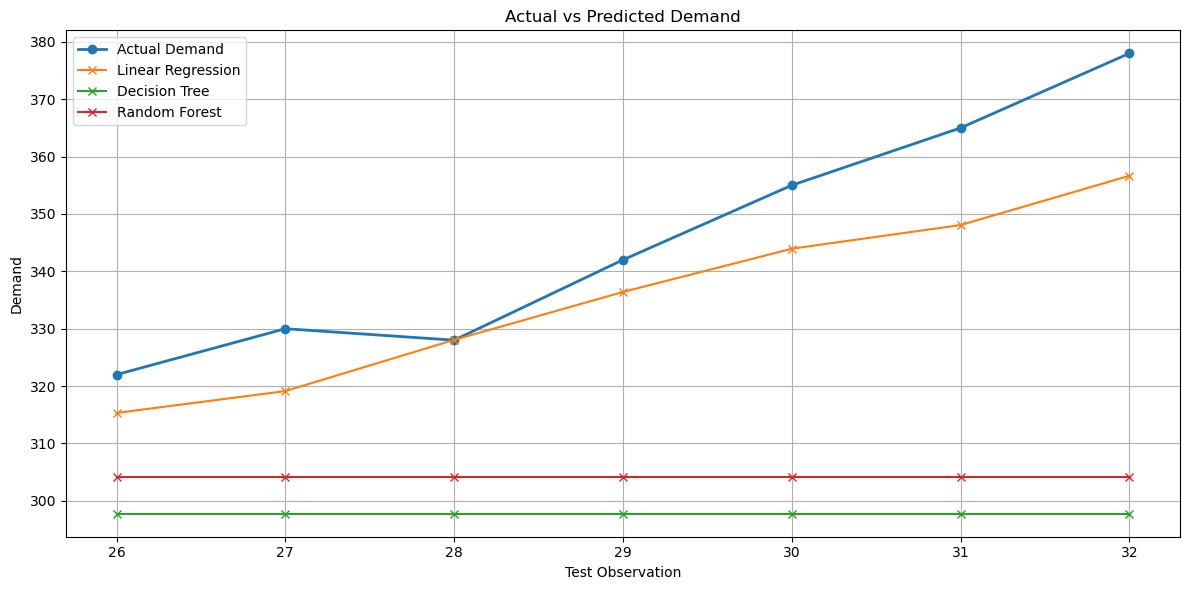

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    y_test.values,
    marker='o',
    linewidth=2,
    label="Actual Demand"
)

for name, y_pred in predictions.items():

    plt.plot(
        y_test.index,
        y_pred,
        marker='x',
        label=name
    )

plt.xlabel("Test Observation")
plt.ylabel("Demand")

plt.title("Actual vs Predicted Demand")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()